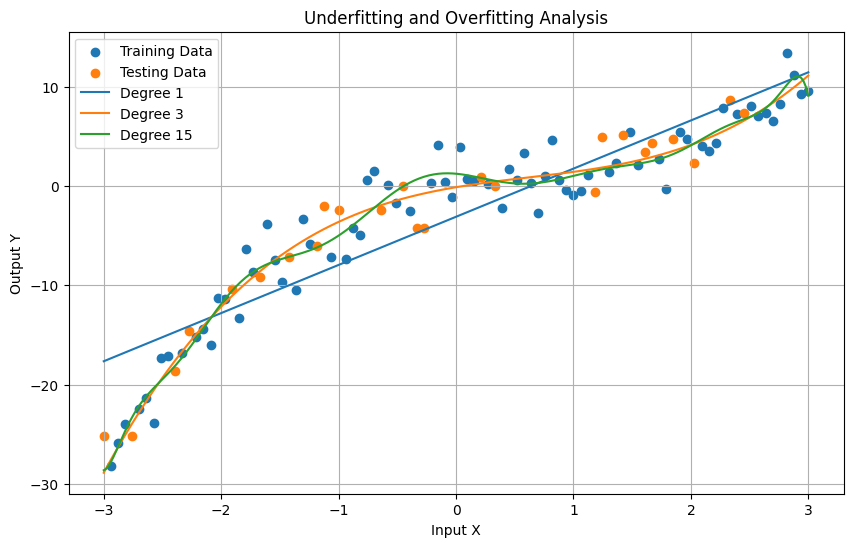


MODEL PERFORMANCE
Degree | Training MSE | Testing MSE
     1 |       15.025 |     13.511
     3 |        4.232 |      3.714
    15 |        3.700 |      5.384


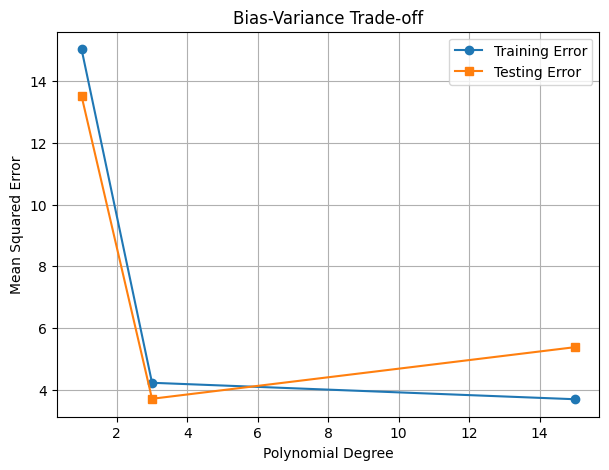

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# 1. Generate dataset
np.random.seed(7)

X = np.linspace(-3, 3, 100).reshape(-1, 1)

y = (
    0.5 * X[:, 0]**3
    - X[:, 0]**2
    + 2 * X[:, 0]
    + np.random.normal(0, 2, 100)
)

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# 3. Different polynomial degrees
degrees = [1, 3, 15]

results = []

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train, y_train,
    label="Training Data"
)

plt.scatter(
    X_test, y_test,
    label="Testing Data"
)

x_plot = np.linspace(
    -3, 3, 300
).reshape(-1, 1)

# 4. Train models
for degree in degrees:

    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)

    test_prediction = model.predict(X_test)

    train_error = mean_squared_error(
        y_train,
        train_prediction
    )

    test_error = mean_squared_error(
        y_test,
        test_prediction
    )

    results.append(
        (degree, train_error, test_error)
    )

    plt.plot(
        x_plot,
        model.predict(x_plot),
        label=f"Degree {degree}"
    )

# 5. Display graph
plt.xlabel("Input X")
plt.ylabel("Output Y")

plt.title(
    "Underfitting and Overfitting Analysis"
)

plt.legend()
plt.grid()

plt.show()

# 6. Print error comparison
print("\nMODEL PERFORMANCE")

print("Degree | Training MSE | Testing MSE")

for degree, train_error, test_error in results:

    print(
        f"{degree:6d} | "
        f"{train_error:12.3f} | "
        f"{test_error:10.3f}"
    )

# 7. Bias-Variance graph
degrees_result = [r[0] for r in results]

train_errors = [r[1] for r in results]

test_errors = [r[2] for r in results]

plt.figure(figsize=(7, 5))

plt.plot(
    degrees_result,
    train_errors,
    marker="o",
    label="Training Error"
)

plt.plot(
    degrees_result,
    test_errors,
    marker="s",
    label="Testing Error"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")

plt.title("Bias-Variance Trade-off")

plt.legend()
plt.grid()

plt.show()